# EDA 02: Playoff Player Stats (2015-16 to 2025-26)

Exploratory data analysis of the playoff player features built in `New-Cleaning/player-stats/`. It reads **`data-files/02-processed/player_stats_combined.csv`** (from `999_combining`), so run that pipeline first. It compares the playoffs with the regular season where that helps (see also `01-Regular-Season-EDA.ipynb`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths to the shared data-files/ folder (and the cleaning helpers) live in New-Cleaning/salary-data.
sys.path.insert(0, str(Path('..') / '..' / 'New-Cleaning' / 'salary-data'))
from nba_cleaning_utils import PROCESSED, prior_seasons_average

def flag_iqr(series):
    """True for values outside 1.5 x IQR of the series (used within each season)."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

# One table with every player feature, built by New-Cleaning/player-stats/999_combining.ipynb
stats = pd.read_csv(PROCESSED / 'player_stats_combined.csv', dtype={'nba_player_id': str})
avg_cols = ['seasons_played_last_3', 'avg_ppg_last_3', 'avg_rpg_last_3', 'avg_apg_last_3',
            'avg_bpm_last_3', 'avg_mpg_last_3', 'avg_gp_last_3']
stat_names = ['gp', 'mpg', 'ppg', 'rpg', 'apg', 'bpg', 'spg', 'ts_pct', 'bpm', 'plus_minus']

def season_view(prefix, min_gp, max_gp):
    """Rows with at least min_gp games of this season type, with plain column names and the EDA flags."""
    view = (stats[stats[f'{prefix}_gp'] >= min_gp]
            .rename(columns={'nba_player_id': 'player_id', **{f'{prefix}_{c}': c for c in stat_names}})
            [['season', 'player_id', 'player_name', 'age', 'years_in_nba'] + stat_names + avg_cols]
            .reset_index(drop=True))
    view['ppg_outlier'] = view.groupby('season')['ppg'].transform(flag_iqr)
    view['suspicious_entry'] = (view['ts_pct'].isna() | (view['ts_pct'] <= 0) | (view['ts_pct'] > 1) | (view['gp'] > max_gp))
    return view

# Regular season: 10+ games. Playoffs: 4+ games (one full series).
df_regular_clean = season_view('rs', min_gp=10, max_gp=82)
df_playoffs_clean = season_view('po', min_gp=4, max_gp=28)
print('regular-season rows (10+ games):', df_regular_clean.shape, '| playoff rows (4+ games):', df_playoffs_clean.shape)

regular-season rows (10+ games): (5254, 24) | playoff rows (4+ games): (1974, 24)


## How this notebook works

* **Rows:** player-postseasons with at least **4 playoff games** (one full series), 1,974 of them. For comparisons, regular-season rows with at least 10 games, the same as EDA 01.
* **Columns:** the `po_` prefix is dropped (`po_ppg` → `ppg`, ...). `bpm` is Basketball-Reference Box Plus/Minus and `plus_minus` is on-court plus/minus per game.
* **Flags, recomputed here:** `ppg_outlier` uses the 1.5 × IQR rule within each postseason. `suspicious_entry` marks a true shooting % of 0 or above 1, or more than 28 games. The 24 suspicious rows are left out of correlations and the trend analysis.
* We work on a copy named `po_eda`, and helper variables start with `po_eda_`.
* **Every number used in the findings is printed** by a code cell, not only shown in a chart, so the text can be checked against the output.

In [2]:
po_eda = df_playoffs_clean.copy()
po_eda_no_susp = po_eda[~po_eda['suspicious_entry']].copy()
po_eda_reg = df_regular_clean[~df_regular_clean['suspicious_entry']]    # regular season, for comparisons

print(f"Playoff EDA rows: {len(po_eda):,}")
print(f"PPG outliers: {po_eda['ppg_outlier'].sum()}")
print(f"Suspicious rows left out of correlations and trends: {po_eda['suspicious_entry'].sum()}")
print(f"Rows used for correlations: {len(po_eda_no_susp):,}")
print(f"Unique players: {po_eda['player_id'].nunique():,}")

Playoff EDA rows: 1,974
PPG outliers: 43
Suspicious rows left out of correlations and trends: 24
Rows used for correlations: 1,950
Unique players: 724


## 1. Distributions of the performance stats

The same stats as EDA 01. The last column is the regular-season median for comparison. Remember that the two groups are different players: only playoff teams, and coaches shorten their rotations.

,Mean,Median,Std Dev,Skewness,RS Median
ppg,9.658,7.750,7.709,0.993,7.709
rpg,3.901,3.250,2.864,1.098,3.283
apg,2.020,1.261,2.072,1.659,1.481
bpg,0.424,0.262,0.480,2.077,0.304
spg,0.653,0.511,0.534,0.998,0.608
mpg,22.120,22.655,11.846,-0.110,20.464
gp,9.524,7.000,5.440,0.996,57.000
ts_pct,0.540,0.551,0.126,-0.590,0.556
plus_minus,-1.272,-0.667,5.042,-0.720,-0.382
bpm,-0.105,0.100,5.292,-0.058,-1.100


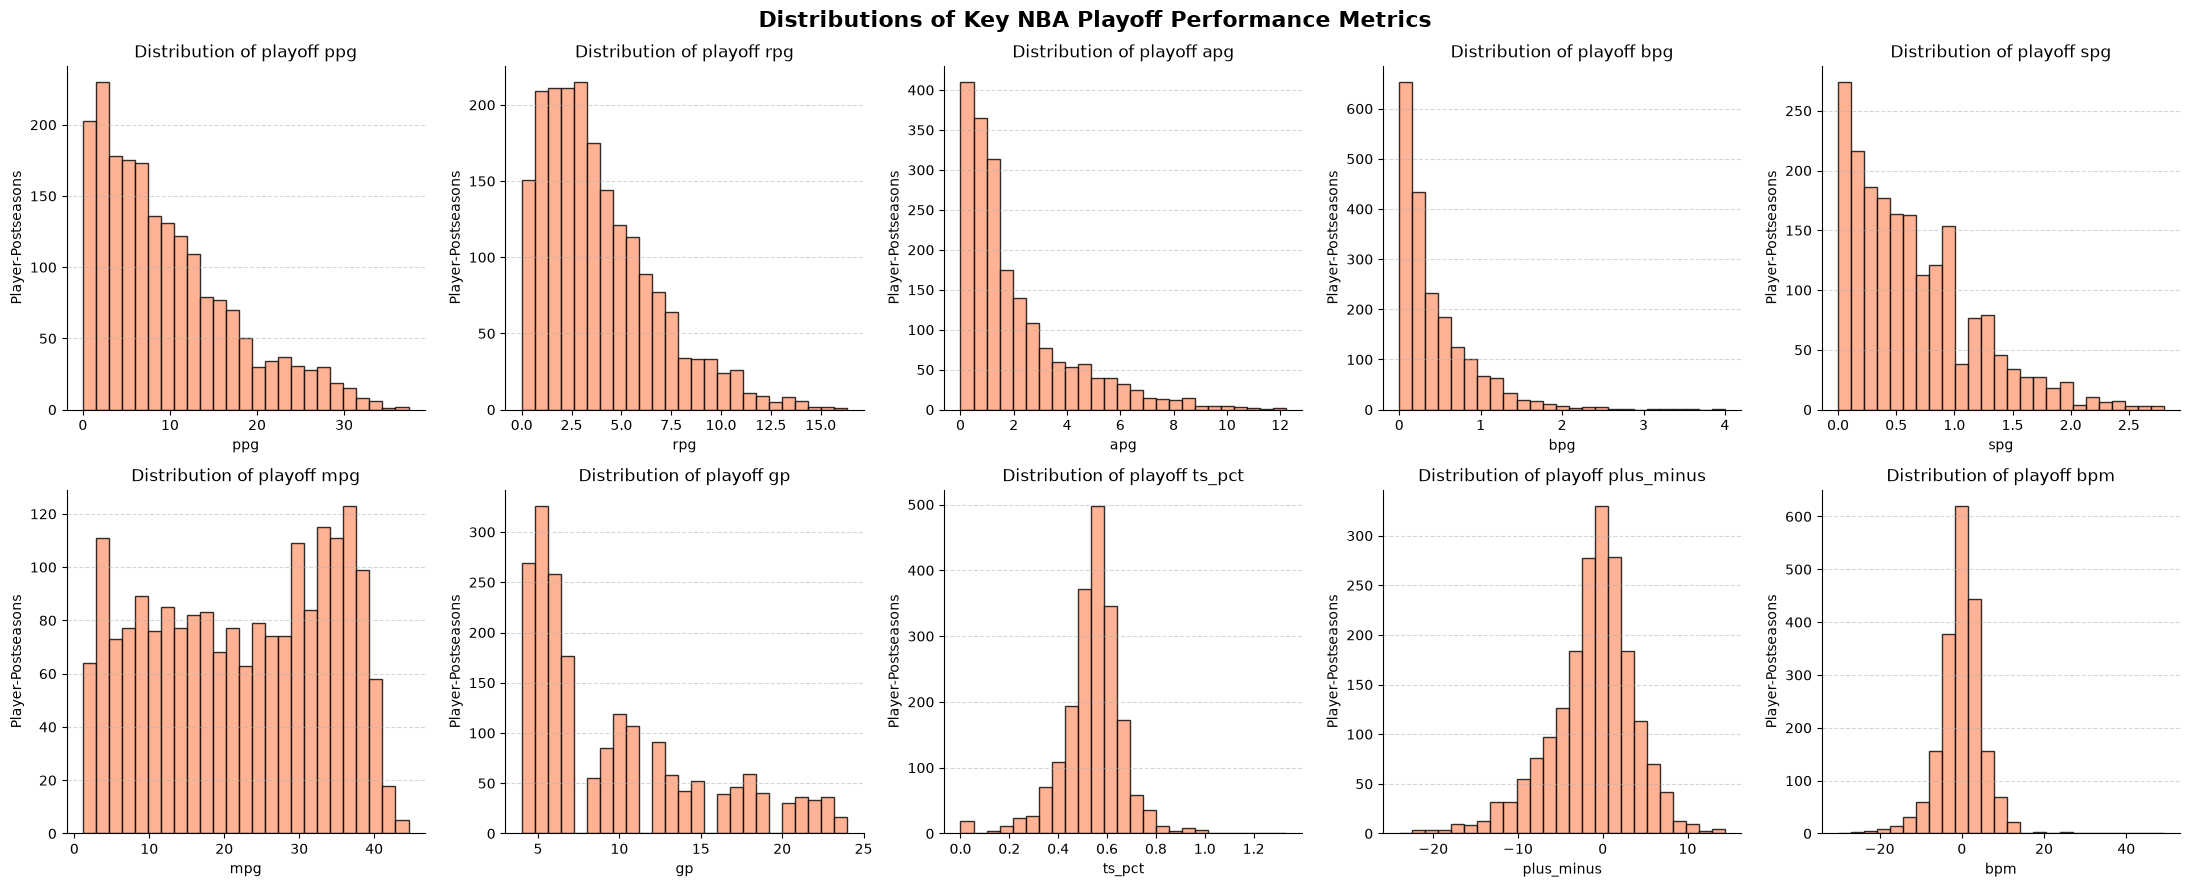

In [3]:
po_eda_stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'bpm']

po_eda_summary = pd.DataFrame({
    'Mean': po_eda[po_eda_stat_cols].mean(),
    'Median': po_eda[po_eda_stat_cols].median(),
    'Std Dev': po_eda[po_eda_stat_cols].std(),
    'Skewness': po_eda[po_eda_stat_cols].skew(),
    'RS Median': df_regular_clean[po_eda_stat_cols].median(),
})
display(po_eda_summary.round(3))

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.ravel()
for i, col in enumerate(po_eda_stat_cols):
    axes[i].hist(po_eda[col], bins=25, color='lightsalmon', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Distribution of playoff {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Player-Postseasons')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)
plt.suptitle('Distributions of Key NBA Playoff Performance Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found

* **Right-skewed stats:** `bpg` (skew 2.08), `apg` (1.66), `rpg` (1.10), `spg` (1.00), and `ppg` (0.99) are right-skewed, as in the regular season. For example, `ppg` has a mean of 9.66 and a median of 7.75.
* **Games played is right-skewed too (skew 1.00):** the median is 7 games and the mean 9.52. Most teams go out in the first round or two, so only the teams that go deep play many games. In the regular season, by contrast, `gp` mostly reflects role and health.
* **Close to symmetric:** `mpg` (skew −0.11) has a median of 22.7, compared with 20.5 in the regular season, because coaches shorten their rotations and the remaining players play more.
* **True shooting:** the median is 55.1% (regular season 55.6%), and the spread is much wider: a standard deviation of 0.126, compared with 0.069 in EDA 01. Playoff samples are only a few games, so a hot or cold week moves a player's TS% a lot.
* **Plus/minus:** mean −1.27, median −0.67, with a tail on the negative side (skew −0.72). Players on teams that are swept or blown out get large negative values.
* **BPM is higher and more spread out than in the regular season:** median +0.10 (regular season −1.10) and standard deviation 5.29 (vs 3.15). Playoff rotations keep the better players, and short samples spread the values out.
* **Typical scoring is about the same as the regular season** (median 7.75 vs 7.71), but these are different groups of players. The pipeline's `02-llimllib-Playoff-Stats.ipynb` (section 2E) compares the **same** players, whose scoring drops in the playoffs.

## 2. Age and experience

The same charts as EDA 01, with the values behind each line chart printed. The `rows` column shows how many player-postseasons each point is based on, because some playoff groups are small.

Age quartiles: 25% = 24.0, median = 27.0, 75% = 30.0
years_in_nba: most common = 4, median = 6.0
Regular season for comparison: median age = 26.0, median years_in_nba = 4.0


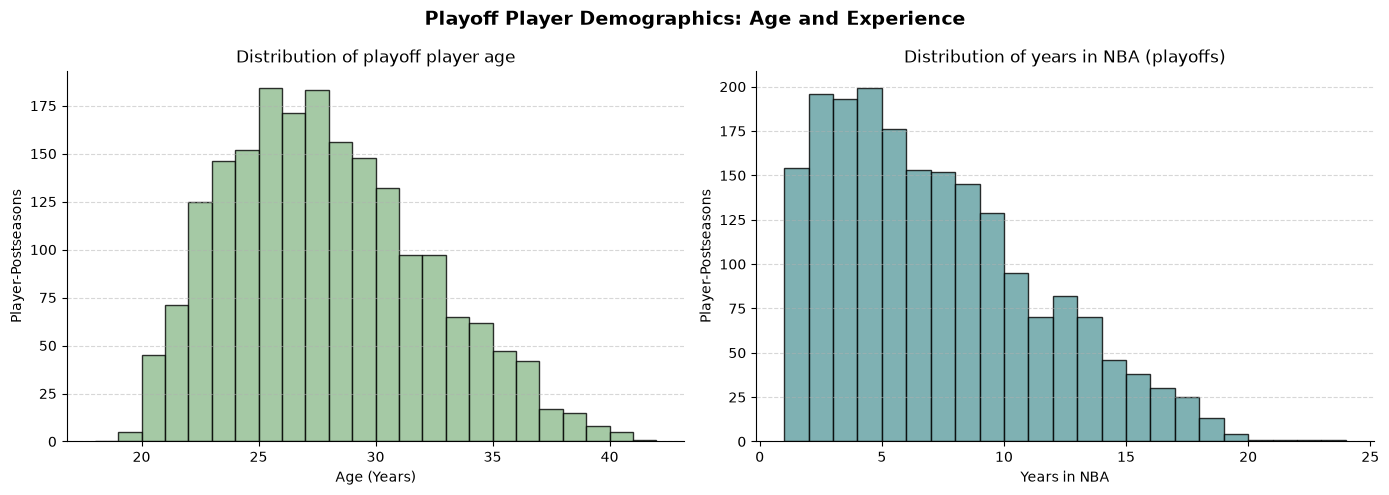


--- Median ppg and mpg by years in NBA ---


,median_ppg,median_mpg,rows
exp_group,,,
1,3.20,9.23,154
2,4.78,14.65,196
3,7.00,20.06,193
4,8.33,23.17,199
5,8.88,24.80,176
6,9.14,24.97,153
7,10.10,26.99,152
8,10.31,27.82,145
9,11.29,29.62,129


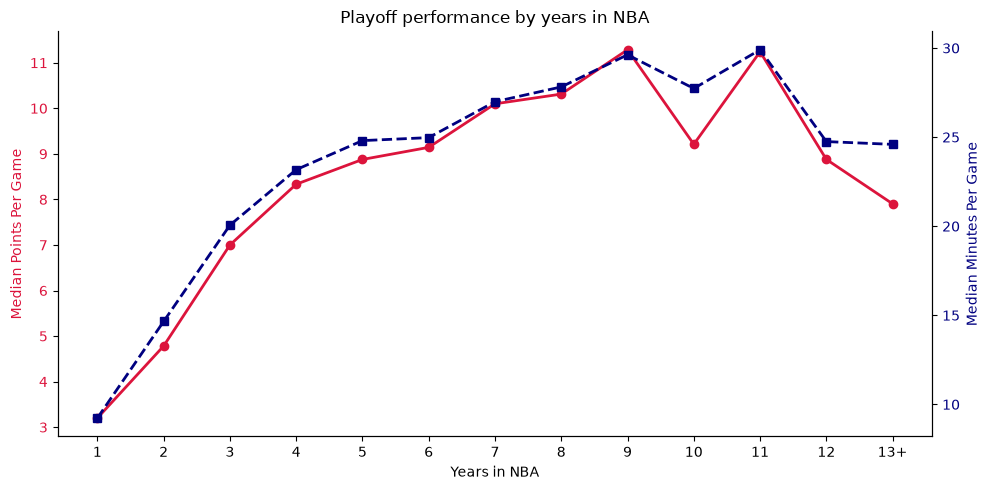


--- Median ppg by age group ---


,median_ppg,rows
age_group,,
21 and under,5.00,121
22,6.00,125
23,7.09,146
24,7.38,152
25,7.49,184
26,8.60,171
27,9.14,183
28,9.55,156
29,8.93,148


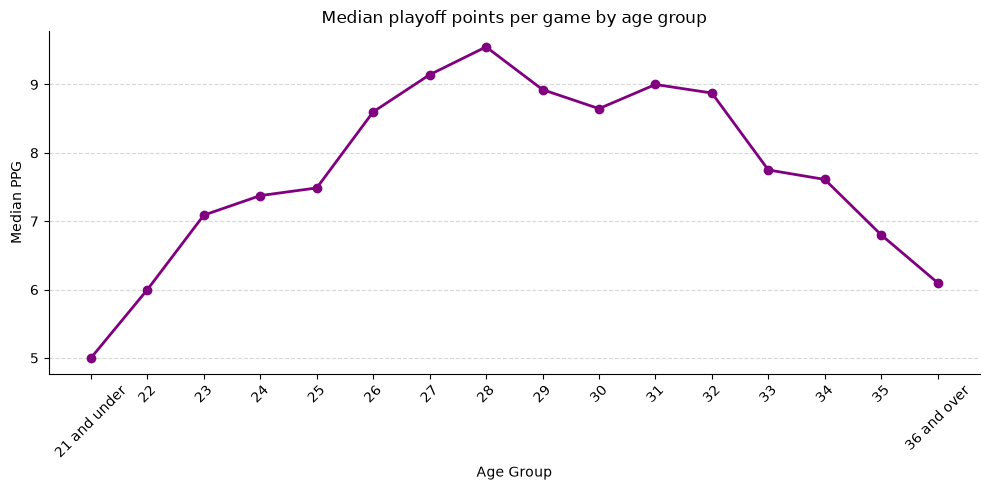

In [4]:
po_eda_years = po_eda['years_in_nba'].dropna()
print(f"Age quartiles: 25% = {po_eda['age'].quantile(0.25)}, median = {po_eda['age'].median()}, 75% = {po_eda['age'].quantile(0.75)}")
print(f"years_in_nba: most common = {po_eda_years.mode()[0]}, median = {po_eda_years.median()}")
print(f"Regular season for comparison: median age = {df_regular_clean['age'].median()}, "
      f"median years_in_nba = {df_regular_clean['years_in_nba'].median()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(po_eda['age'], bins=range(18, 43), color='darkseagreen', edgecolor='black', alpha=0.8)
axes[0].set_title('Distribution of playoff player age')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Player-Postseasons')
axes[1].hist(po_eda_years, bins=range(1, int(po_eda_years.max()) + 2), color='cadetblue', edgecolor='black', alpha=0.8)
axes[1].set_title('Distribution of years in NBA (playoffs)')
axes[1].set_xlabel('Years in NBA')
axes[1].set_ylabel('Player-Postseasons')
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.suptitle('Playoff Player Demographics: Age and Experience', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Median ppg and mpg by years in NBA (13+ grouped), rows with a known years_in_nba only
po_eda_exp = po_eda.dropna(subset=['years_in_nba']).copy()
po_eda_exp['exp_group'] = po_eda_exp['years_in_nba'].apply(lambda x: '13+' if x >= 13 else str(int(x)))
po_eda_exp_order = [str(i) for i in range(1, 13)] + ['13+']
po_eda_exp_grouped = (po_eda_exp.groupby('exp_group')
                      .agg(median_ppg=('ppg', 'median'), median_mpg=('mpg', 'median'), rows=('ppg', 'size'))
                      .reindex(po_eda_exp_order))
po_eda_exp_grouped['rows'] = po_eda_exp_grouped['rows'].astype('Int64')
print("\n--- Median ppg and mpg by years in NBA ---")
display(po_eda_exp_grouped.round(2))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Years in NBA')
ax1.set_ylabel('Median Points Per Game', color='crimson')
ax1.plot(po_eda_exp_grouped.index, po_eda_exp_grouped['median_ppg'], marker='o', color='crimson', linewidth=2)
ax1.tick_params(axis='y', labelcolor='crimson')
ax1.spines['top'].set_visible(False)
ax2 = ax1.twinx()
ax2.set_ylabel('Median Minutes Per Game', color='navy')
ax2.plot(po_eda_exp_grouped.index, po_eda_exp_grouped['median_mpg'], marker='s', linestyle='--', color='navy', linewidth=2)
ax2.tick_params(axis='y', labelcolor='navy')
ax2.spines['top'].set_visible(False)
plt.title('Playoff performance by years in NBA')
plt.tight_layout()
plt.show()

# Median ppg by age group (same groups as 6B)
def po_eda_age_group(a):
    if a <= 21:
        return '21 and under'
    elif a >= 36:
        return '36 and over'
    return str(int(a))

po_eda['age_group'] = po_eda['age'].apply(po_eda_age_group)
po_eda_age_order = ['21 and under'] + [str(i) for i in range(22, 36)] + ['36 and over']
po_eda_age_grouped = (po_eda.groupby('age_group')
                      .agg(median_ppg=('ppg', 'median'), rows=('ppg', 'size'))
                      .reindex(po_eda_age_order))
po_eda_age_grouped['rows'] = po_eda_age_grouped['rows'].astype('Int64')
print("\n--- Median ppg by age group ---")
display(po_eda_age_grouped.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(po_eda_age_grouped.index, po_eda_age_grouped['median_ppg'], marker='o', color='purple', linewidth=2)
ax.set_title('Median playoff points per game by age group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Median PPG')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Older and more experienced than the regular season:** the middle half of playoff player-postseasons are between 24 and 30 years old (median 27, vs 26 in the regular season). The median `years_in_nba` is 6 (regular season 4), and the most common value is 4.
* **Experience:** median playoff `ppg` rises from 3.20 in a player's first year to 11.29 in year 9, then stays between 7.90 and 11.24 for years 10 to 13+. Median `mpg` follows the same shape: 9.23 in year 1, about 29.6-29.9 in years 9 and 11, and 24.59 for 13+. As in EDA 01, part of this rise is survivor bias.
* **Age:** median `ppg` rises from 5.00 for players 21 and under to a peak of 9.55 at age 28. It stays between 8.60 and 9.55 from 26 to 32, then falls to 6.10 for players 36 and over (88 rows).
* **Every row has `years_in_nba`** (counted from the player's first game), so nobody is left out of the experience charts.

## 3. Playing time

The same minute groups as EDA 01. The correlation leaves out the suspicious rows.

,count,median_ppg,median_ts_pct,median_plus_minus
mpg_bin,,,,
0-10,420,1.577,0.500,-0.500
10-20,454,4.750,0.542,-0.667
20-30,444,9.167,0.556,-0.955
30+,656,16.866,0.563,-0.793


Correlation between mpg and ppg (playoffs, without suspicious rows): 0.8613
Same correlation in the regular season: 0.8752
Scoring outliers: 43, lowest mpg among them: 34.13, fewest games among them: 4


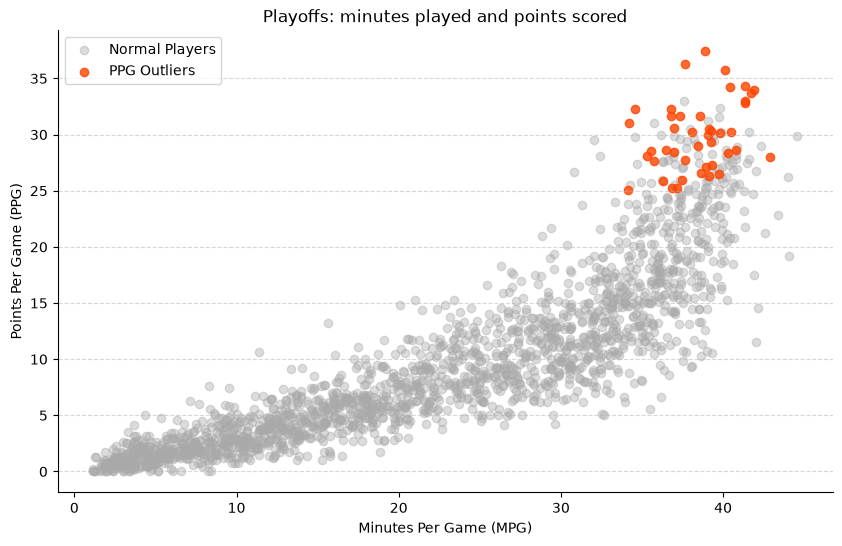

In [5]:
def po_eda_bin_mpg(m):
    if m < 10:
        return '0-10'
    elif m < 20:
        return '10-20'
    elif m < 30:
        return '20-30'
    return '30+'

po_eda['mpg_bin'] = po_eda['mpg'].apply(po_eda_bin_mpg)
po_eda_mpg_grouped = po_eda.groupby('mpg_bin').agg(
    count=('ppg', 'count'),
    median_ppg=('ppg', 'median'),
    median_ts_pct=('ts_pct', 'median'),
    median_plus_minus=('plus_minus', 'median'),
).reindex(['0-10', '10-20', '20-30', '30+'])
display(po_eda_mpg_grouped.round(3))

po_eda_corr_mpg_ppg = po_eda_no_susp['mpg'].corr(po_eda_no_susp['ppg'])
po_eda_reg_corr_mpg_ppg = po_eda_reg['mpg'].corr(po_eda_reg['ppg'])
print(f"Correlation between mpg and ppg (playoffs, without suspicious rows): {po_eda_corr_mpg_ppg:.4f}")
print(f"Same correlation in the regular season: {po_eda_reg_corr_mpg_ppg:.4f}")

po_eda_outliers = po_eda[po_eda['ppg_outlier']]
print(f"Scoring outliers: {len(po_eda_outliers)}, lowest mpg among them: {po_eda_outliers['mpg'].min():.2f}, "
      f"fewest games among them: {po_eda_outliers['gp'].min():.0f}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(po_eda[~po_eda['ppg_outlier']]['mpg'], po_eda[~po_eda['ppg_outlier']]['ppg'],
           alpha=0.4, color='darkgray', label='Normal Players')
ax.scatter(po_eda_outliers['mpg'], po_eda_outliers['ppg'], alpha=0.8, color='orangered', label='PPG Outliers')
ax.set_title('Playoffs: minutes played and points scored')
ax.set_xlabel('Minutes Per Game (MPG)')
ax.set_ylabel('Points Per Game (PPG)')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **More players play big minutes:** 656 of 1,974 playoff rows (about a third) are in the 30+ minute group, compared with 1,004 of 5,254 (about a fifth) in the regular season. This matches section 1: coaches shorten their rotations.
* **Bigger roles score more and shoot better:** from 0-10 minutes to 30+, median `ppg` goes from 1.58 to 16.87 and median `ts_pct` from 50.0% to 56.3%.
* **Plus/minus is negative in every minute group:** the medians are −0.50, −0.67, −0.96, and −0.79. In the regular season, the 30+ group was positive (+1.65). In the playoffs every team plays good teams, and half of all games are losses.
* **Minutes and points still go together:** the correlation between `mpg` and `ppg` is 0.861, slightly below the regular season's 0.875.
* **Scoring outliers:** all 43 playoff scoring outliers play at least 34.13 minutes per game, and the fewest games among them is 4.

## 4. Relationships between variables

Correlation heatmap, without the suspicious rows. The pair table lists each pair of variables **once**, with the regular-season correlation next to it.

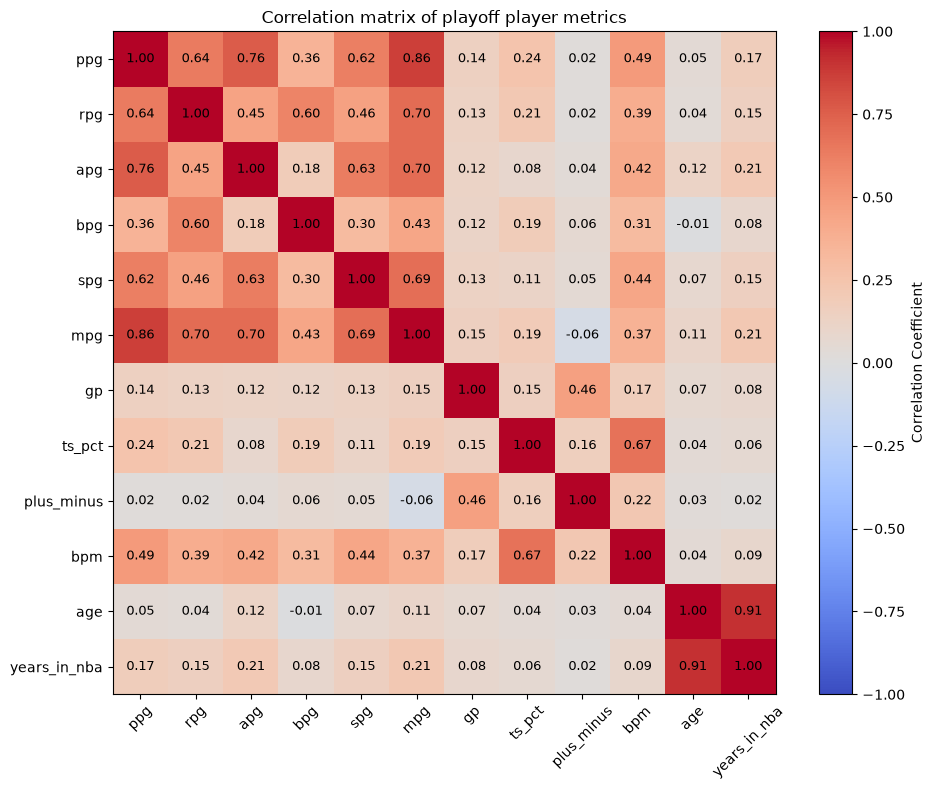

--- Top 5 strongest playoff correlation pairs ---


,var_1,var_2,playoff_corr,regular_season_corr,difference
0,age,years_in_nba,0.912,0.901,0.012
1,ppg,mpg,0.861,0.875,-0.014
2,ppg,apg,0.758,0.714,0.044
3,rpg,mpg,0.701,0.639,0.062
4,apg,mpg,0.698,0.690,0.008


--- 3 pairs that changed most from the regular season ---


,var_1,var_2,playoff_corr,regular_season_corr,difference
0,mpg,gp,0.154,0.598,-0.444
1,ppg,gp,0.141,0.456,-0.315
2,plus_minus,bpm,0.224,0.514,-0.290


Correlation between ppg and plus_minus: playoffs 0.02, regular season 0.27
Correlation between ppg and bpm: playoffs 0.49, regular season 0.65
Playoff 20+ ppg scorers: 234, with negative plus_minus: 110 (47%); with negative bpm: 16 (7%)


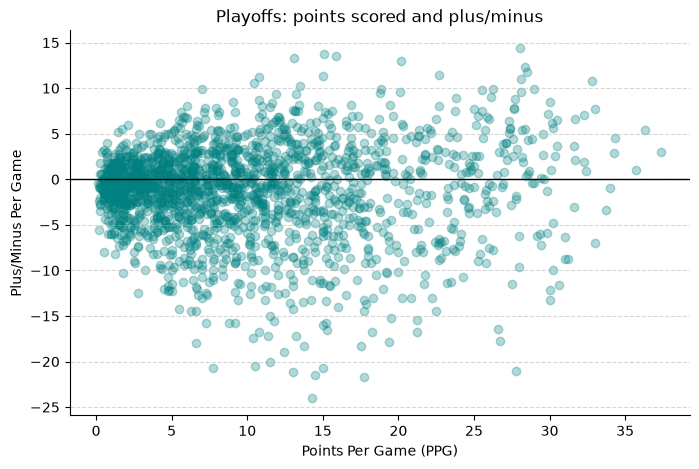

In [6]:
po_eda_corr_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'bpm', 'age', 'years_in_nba']
po_eda_corr_matrix = po_eda_no_susp[po_eda_corr_cols].corr()
po_eda_reg_corr_matrix = po_eda_reg[po_eda_corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(po_eda_corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)
for i in range(len(po_eda_corr_cols)):
    for j in range(len(po_eda_corr_cols)):
        ax.text(j, i, f"{po_eda_corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_xticks(range(len(po_eda_corr_cols)))
ax.set_yticks(range(len(po_eda_corr_cols)))
ax.set_xticklabels(po_eda_corr_cols, rotation=45)
ax.set_yticklabels(po_eda_corr_cols)
fig.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.title('Correlation matrix of playoff player metrics')
plt.tight_layout()
plt.show()

# Every pair once (upper triangle), sorted by strength
po_eda_pairs = pd.DataFrame(
    [(a, b, po_eda_corr_matrix.loc[a, b], po_eda_reg_corr_matrix.loc[a, b])
     for i, a in enumerate(po_eda_corr_cols) for b in po_eda_corr_cols[i + 1:]],
    columns=['var_1', 'var_2', 'playoff_corr', 'regular_season_corr'])
po_eda_pairs['difference'] = po_eda_pairs['playoff_corr'] - po_eda_pairs['regular_season_corr']
po_eda_top_pairs = po_eda_pairs.reindex(po_eda_pairs['playoff_corr'].abs().sort_values(ascending=False).index).head(5)
print("--- Top 5 strongest playoff correlation pairs ---")
display(po_eda_top_pairs.round(3).reset_index(drop=True))
print("--- 3 pairs that changed most from the regular season ---")
display(po_eda_pairs.reindex(po_eda_pairs['difference'].abs().sort_values(ascending=False).index).head(3).round(3).reset_index(drop=True))

po_eda_corr_ppg_pm = po_eda_no_susp['ppg'].corr(po_eda_no_susp['plus_minus'])
print(f"Correlation between ppg and plus_minus: playoffs {po_eda_corr_ppg_pm:.2f}, "
      f"regular season {po_eda_reg['ppg'].corr(po_eda_reg['plus_minus']):.2f}")
print(f"Correlation between ppg and bpm: playoffs {po_eda_no_susp['ppg'].corr(po_eda_no_susp['bpm']):.2f}, "
      f"regular season {po_eda_reg['ppg'].corr(po_eda_reg['bpm']):.2f}")
po_eda_scorers = po_eda_no_susp[po_eda_no_susp['ppg'] >= 20]
print(f"Playoff 20+ ppg scorers: {len(po_eda_scorers)}, with negative plus_minus: "
      f"{(po_eda_scorers['plus_minus'] < 0).sum()} ({(po_eda_scorers['plus_minus'] < 0).mean():.0%}); with negative bpm: "
      f"{(po_eda_scorers['bpm'] < 0).sum()} ({(po_eda_scorers['bpm'] < 0).mean():.0%})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(po_eda_no_susp['ppg'], po_eda_no_susp['plus_minus'], alpha=0.3, color='teal')
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Playoffs: points scored and plus/minus')
ax.set_xlabel('Points Per Game (PPG)')
ax.set_ylabel('Plus/Minus Per Game')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strongest pairs:** `age` & `years_in_nba` (0.912), `ppg` & `mpg` (0.861), `ppg` & `apg` (0.758), `rpg` & `mpg` (0.701), and `apg` & `mpg` (0.698). These are almost the same as in the regular season; the biggest difference among them is `rpg` & `mpg` (0.701 vs 0.639).
* **Games played changes meaning in the playoffs:** the two pairs that changed most involve `gp`. Its correlation with `mpg` drops from 0.598 to 0.154, and with `ppg` from 0.456 to 0.141. In the regular season, more games usually means a bigger, steadier role. In the playoffs, the number of games mostly depends on how far the team goes.
* **On-court plus/minus and BPM drift apart in the playoffs** (correlation 0.514 in the regular season, 0.224 in the playoffs). Playoff plus/minus is dominated by the matchup and the series result.
* **Scoring predicts BPM, not plus/minus:** the correlation between `ppg` and `plus_minus` is 0.02 in the playoffs (0.27 in the regular season), but between `ppg` and `bpm` it is 0.49 (0.65). Of the 234 player-postseasons with 20+ `ppg`, 110 (47%) have a negative `plus_minus`, but only 16 (7%) have a negative `bpm`. A team's top scorers are on the court for most of its losses, so plus/minus reflects the matchup more than the scorer.
* **Collinearity:** as in EDA 01, `age` and `years_in_nba` carry nearly the same information, and most box-score stats rise with minutes.

## 5. Playoff changes over time

Season-by-season averages, printed as a table. Note:
* `mean_ts_pct` is the **average of players' TS%**, with every player counted equally. It isn't the league's overall playoff TS%.
* The 2020 postseason (2019-20) was played in the Orlando "bubble" with no home crowds.

,rows,mean_ppg,median_ppg,mean_ts_pct,mean_mpg,rs_mean_ts_pct
season,,,,,,
2016,189,8.508,6.750,0.510,21.151,0.530
2017,175,9.646,7.571,0.540,22.203,0.537
2018,176,9.667,8.203,0.535,22.424,0.540
2019,179,9.589,7.727,0.532,22.009,0.544
2020,162,10.832,9.110,0.551,24.168,0.553
2021,192,9.626,7.200,0.549,21.165,0.556
2022,187,9.414,8.000,0.551,21.532,0.552
2023,174,10.081,8.026,0.549,22.652,0.568
2024,170,10.137,7.929,0.533,23.415,0.564


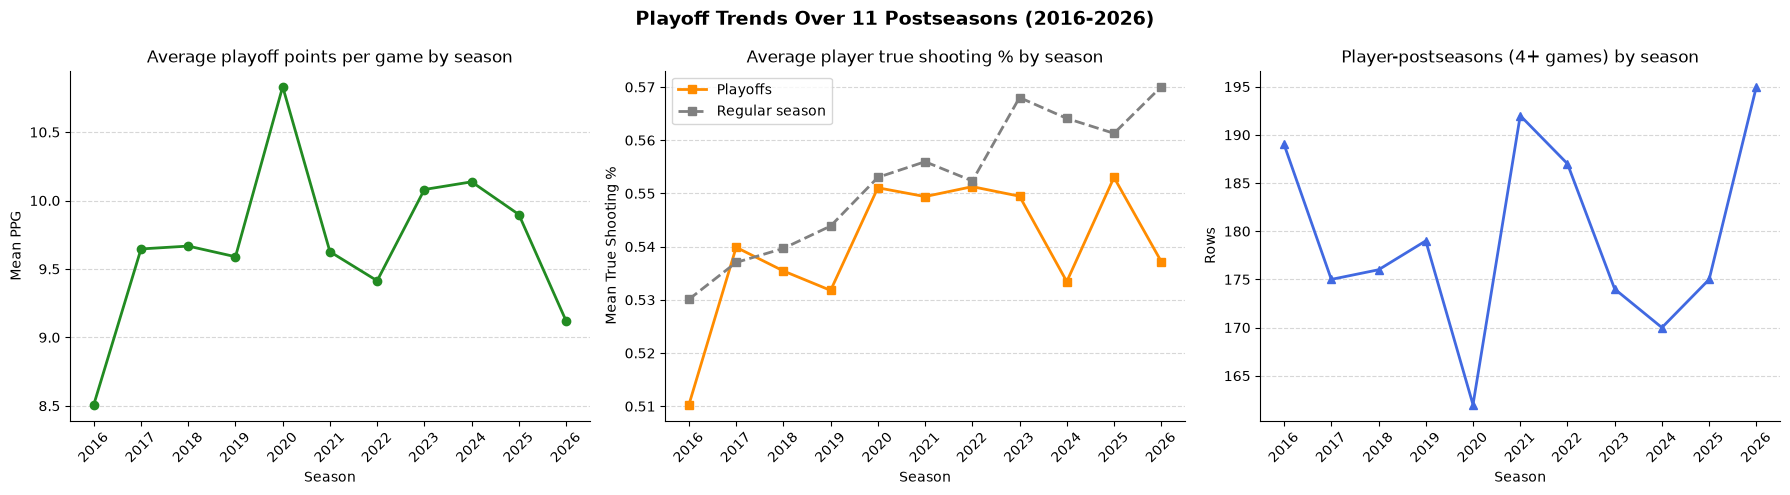

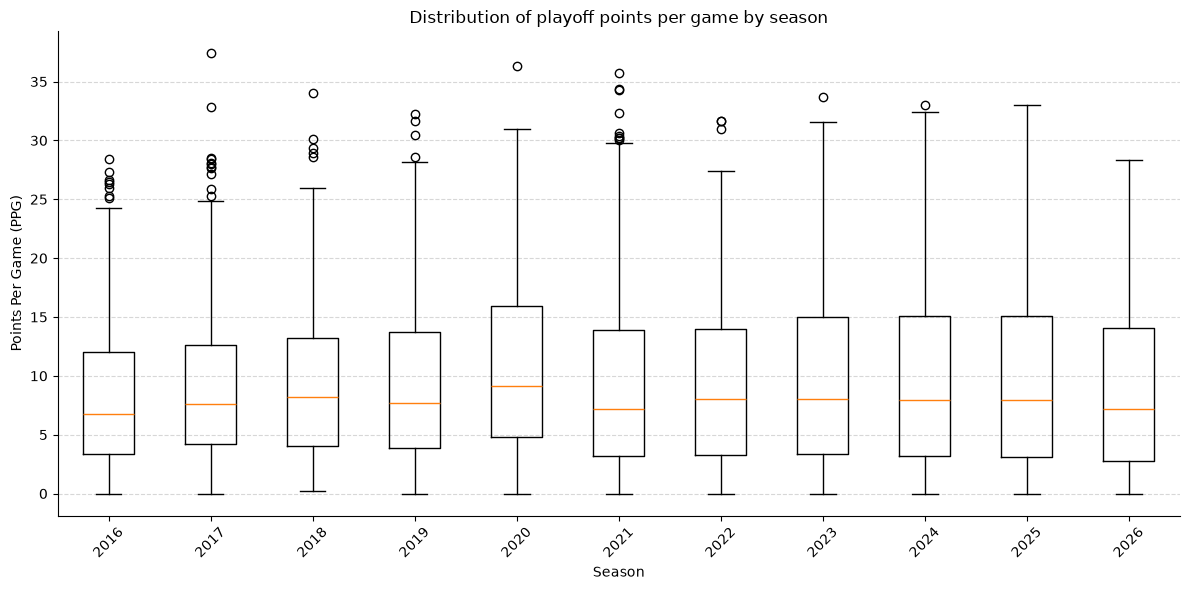

In [7]:
po_eda_season_trends = po_eda.groupby('season').agg(
    rows=('player_id', 'count'),
    mean_ppg=('ppg', 'mean'),
    median_ppg=('ppg', 'median'),
    mean_ts_pct=('ts_pct', 'mean'),
    mean_mpg=('mpg', 'mean'),
).sort_index()
po_eda_season_trends['rs_mean_ts_pct'] = df_regular_clean.groupby('season')['ts_pct'].mean()
display(po_eda_season_trends.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(po_eda_season_trends.index, po_eda_season_trends['mean_ppg'], marker='o', color='forestgreen', linewidth=2)
axes[0].set_title('Average playoff points per game by season')
axes[0].set_ylabel('Mean PPG')
axes[1].plot(po_eda_season_trends.index, po_eda_season_trends['mean_ts_pct'], marker='s', color='darkorange', linewidth=2, label='Playoffs')
axes[1].plot(po_eda_season_trends.index, po_eda_season_trends['rs_mean_ts_pct'], marker='s', linestyle='--', color='gray', linewidth=2, label='Regular season')
axes[1].set_title('Average player true shooting % by season')
axes[1].set_ylabel('Mean True Shooting %')
axes[1].legend()
axes[2].plot(po_eda_season_trends.index, po_eda_season_trends['rows'], marker='^', color='royalblue', linewidth=2)
axes[2].set_title('Player-postseasons (4+ games) by season')
axes[2].set_ylabel('Rows')
for ax in axes:
    ax.set_xlabel('Season')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_xticks(po_eda_season_trends.index)
    ax.set_xticklabels([str(x) for x in po_eda_season_trends.index], rotation=45)
plt.suptitle('Playoff Trends Over 11 Postseasons (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

po_eda_seasons = sorted(po_eda['season'].unique())
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot([po_eda[po_eda['season'] == s]['ppg'] for s in po_eda_seasons])
ax.set_xticks(range(1, len(po_eda_seasons) + 1))
ax.set_xticklabels([str(s) for s in po_eda_seasons])
ax.set_title('Distribution of playoff points per game by season')
ax.set_xlabel('Season')
ax.set_ylabel('Points Per Game (PPG)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Player-postseasons per year** (4+ games) range from 162 (2020) to 195 (2026).
* **Playoff shooting is below the regular season almost every year:** average player TS% is lower in the playoffs in 10 of the 11 seasons. The exception is 2017 (54.0% vs 53.7%). The biggest gaps are 2026 (53.7% vs 57.0%) and 2024 (53.3% vs 56.4%). Regular-season TS% rises over the period, but playoff TS% doesn't follow it closely: it ranges from 51.0% (2016) to 55.3% (2025) with no steady direction.
* **Scoring:** average playoff `ppg` is lowest in 2016 (8.51) and highest in 2020 (10.83). In the other years it's between 9.1 and 10.2.
* **2020 stands out:** it has the highest average `ppg` (10.83) and `mpg` (24.17), and the fewest player-postseasons (162). That was the bubble postseason. This table alone can't show whether the bubble caused it.

## 6. Previous-postseason averages

The pipeline keeps 3-year averages for the **regular season only**. A playoff version would need the player to have been in the playoffs in each of the previous three seasons. This section works out that playoff version here, with the same rule (the previous three seasons, the ones he played, current season excluded), to show why.

* Any playoff appearance counts as a previous postseason, even 1-3 games.
* The table starts in 2015-16, so all three previous postseasons are only available **from 2018-19 on**. This section uses those 8 postseasons.

Playoff rows from 2018-19 on: 1,434; with all 3 previous postseasons (no suspicious entries): 265 (18.5%)

--- Change from the average of the 3 previous postseasons ---


,ppg_vs_prev,mpg_vs_prev,gp_vs_prev
count,265.000,265.000,265.000
mean,-0.021,0.054,-0.208
std,4.452,6.875,6.712
min,-11.969,-21.119,-15.000
25%,-2.774,-3.716,-5.333
50%,-0.198,-0.004,-1.000
75%,2.600,2.884,4.667
max,14.025,23.112,14.667


Postseasons at least 3 ppg ABOVE the previous-3 average: 57 (21.5%)
Postseasons at least 3 ppg BELOW the previous-3 average: 59 (22.3%)
Regular season, same rule: std dev of ppg change 3.559 vs playoffs 4.452


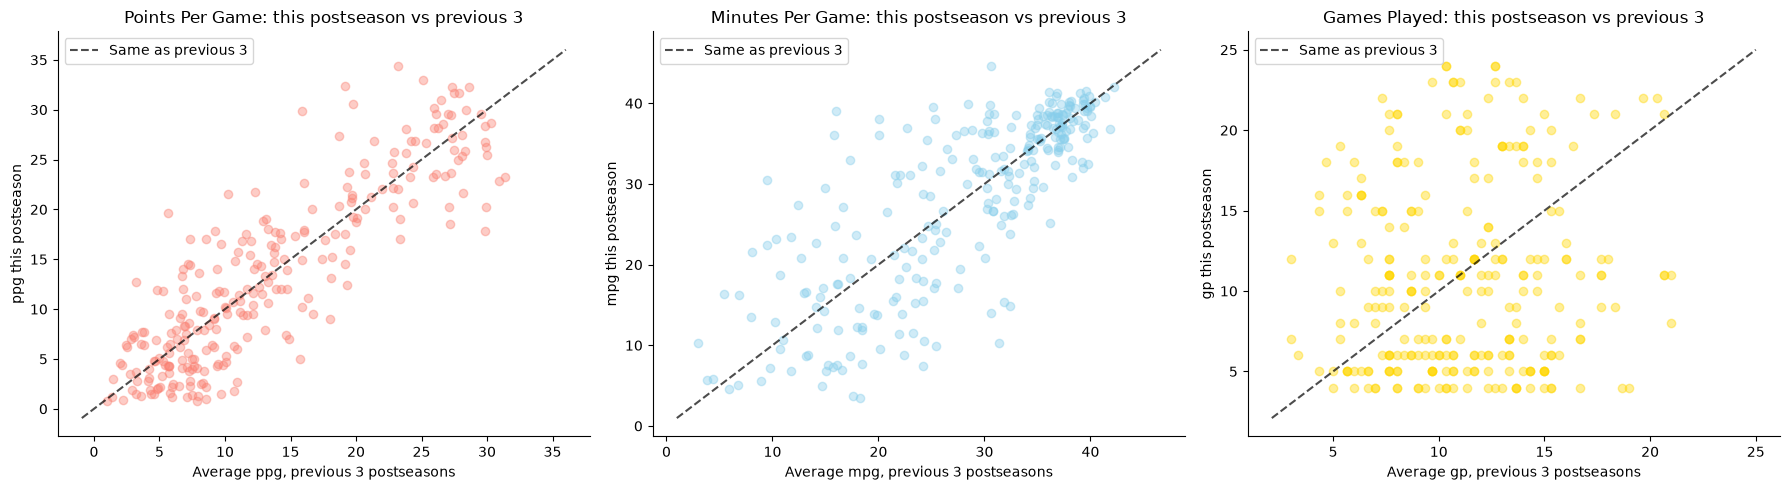


Playoff rows (2018-19 on) with no previous postseason in the last 3 seasons: 378 of 1,434 (26.4%); with all 3: 18.5%
--- Share of rows (%) by number of previous postseasons, by years in NBA ---


postseasons_last_3,0,1,2,3
exp_bin,,,,
1-2,68.6,31.4,0.0,0.0
3,37.9,32.4,29.7,0.0
4-5,20.3,31.3,31.0,17.4
6-9,14.9,25.9,34.8,24.5
10+,8.2,26.6,30.7,34.5


In [8]:
# Previous-postseason averages, worked out here (the pipeline keeps only regular-season trends).
# Use every playoff row (any number of games), so a short postseason still counts as a previous one.
po_eda_all = (stats[stats['po_gp'].notna()]
              .rename(columns={'nba_player_id': 'player_id', 'po_ppg': 'ppg', 'po_mpg': 'mpg', 'po_gp': 'gp'})
              [['season', 'player_id', 'ppg', 'mpg', 'gp']])
po_eda_prior = (prior_seasons_average(po_eda_all, 'player_id', ['ppg', 'mpg', 'gp'], n=3)
                .rename(columns={'seasons_played_last_3': 'postseasons_last_3', 'avg_ppg_last_3': 'prev_avg_ppg',
                                 'avg_mpg_last_3': 'prev_avg_mpg', 'avg_gp_last_3': 'prev_avg_gp'}))
po_eda = po_eda.merge(po_eda_prior, on=['season', 'player_id'], how='left', validate='one_to_one')

# The table starts in 2015-16, so the three previous postseasons are only all available from 2018-19 on.
po_eda_window = po_eda[po_eda['season'] >= 2019]
po_eda_trend = po_eda_window[(po_eda_window['postseasons_last_3'] == 3) & ~po_eda_window['suspicious_entry']].copy()
print(f"Playoff rows from 2018-19 on: {len(po_eda_window):,}; with all 3 previous postseasons (no suspicious entries): "
      f"{len(po_eda_trend):,} ({len(po_eda_trend) / len(po_eda_window):.1%})")

for stat in ['ppg', 'mpg', 'gp']:
    po_eda_trend[f'{stat}_vs_prev'] = po_eda_trend[stat] - po_eda_trend[f'prev_avg_{stat}']
print("\n--- Change from the average of the 3 previous postseasons ---")
display(po_eda_trend[['ppg_vs_prev', 'mpg_vs_prev', 'gp_vs_prev']].describe().round(3))

po_eda_up3 = (po_eda_trend['ppg_vs_prev'] >= 3).sum()
po_eda_down3 = (po_eda_trend['ppg_vs_prev'] <= -3).sum()
print(f"Postseasons at least 3 ppg ABOVE the previous-3 average: {po_eda_up3} ({po_eda_up3 / len(po_eda_trend):.1%})")
print(f"Postseasons at least 3 ppg BELOW the previous-3 average: {po_eda_down3} ({po_eda_down3 / len(po_eda_trend):.1%})")

# Same comparison for the regular season (same seasons, same rule) for reference
rs_window = po_eda_reg[(po_eda_reg['season'] >= 2019) & (po_eda_reg['seasons_played_last_3'] == 3)]
print(f"Regular season, same rule: std dev of ppg change {(rs_window['ppg'] - rs_window['avg_ppg_last_3']).std():.3f} "
      f"vs playoffs {po_eda_trend['ppg_vs_prev'].std():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, stat, name, color in zip(axes, ['ppg', 'mpg', 'gp'],
                                 ['Points Per Game', 'Minutes Per Game', 'Games Played'],
                                 ['salmon', 'skyblue', 'gold']):
    ax.scatter(po_eda_trend[f'prev_avg_{stat}'], po_eda_trend[stat], alpha=0.4, color=color)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, 'k--', alpha=0.7, label='Same as previous 3')
    ax.set_title(f'{name}: this postseason vs previous 3')
    ax.set_xlabel(f'Average {stat}, previous 3 postseasons')
    ax.set_ylabel(f'{stat} this postseason')
    ax.legend()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# How many previous postseasons do playoff players have? (2018-19 on, by experience)
def po_eda_exp_bin(y):
    if y <= 2:
        return '1-2'
    if y == 3:
        return '3'
    if y <= 5:
        return '4-5'
    if y <= 9:
        return '6-9'
    return '10+'

po_eda_window = po_eda_window.assign(exp_bin=po_eda_window['years_in_nba'].apply(po_eda_exp_bin))
print(f"\nPlayoff rows (2018-19 on) with no previous postseason in the last 3 seasons: "
      f"{(po_eda_window['postseasons_last_3'] == 0).sum():,} of {len(po_eda_window):,} "
      f"({(po_eda_window['postseasons_last_3'] == 0).mean():.1%}); with all 3: {(po_eda_window['postseasons_last_3'] == 3).mean():.1%}")
print("--- Share of rows (%) by number of previous postseasons, by years in NBA ---")
display((pd.crosstab(po_eda_window['exp_bin'], po_eda_window['postseasons_last_3'], normalize='index') * 100)
        .reindex(['1-2', '3', '4-5', '6-9', '10+']).round(1))

### What we found

* **Few players have the history:** of the 1,434 playoff rows from 2018-19 on, only 265 (18.5%) have all three previous postseasons (and no suspicious entry), and 26.4% have none at all. Even among players with 10+ years in the NBA, only 34.5% were in the playoffs in all three previous seasons. Playoff history mostly depends on the team.
* **Playoff scoring is volatile:** compared with the previous three postseasons, the average `ppg` change is about 0 (mean −0.02, median −0.20), but the middle half ranges from −2.77 to +2.60 and the standard deviation is 4.45 points. That is larger than the regular season's 3.56 under the same rule. 57 postseasons (21.5%) are at least 3 `ppg` above the previous average, and 59 (22.3%) at least 3 below. Minutes (standard deviation 6.88) and games played (6.71) move a lot too.
* **This is why the pipeline keeps only regular-season trends:** a playoff trend would be missing for most rows, and noisy where it exists.

## 7. Playoff regulars vs one-time appearances

Counts how many postseasons (with 4+ games) each player has in 2016-2026. Players are counted by `player_id`, not by name, so two players with the same name aren't merged.

Players with 4+ playoff games at least once: 724
Players with 1-2 postseasons: 419 (57.9%); with 6+ postseasons: 77 (10.6%)
Most postseasons by one player: 11

Players in the cleaned regular-season table: 1,315; never in the cleaned playoff table: 597 (45.4%)
Players in the cleaned playoff table but never in the cleaned regular-season table: 6


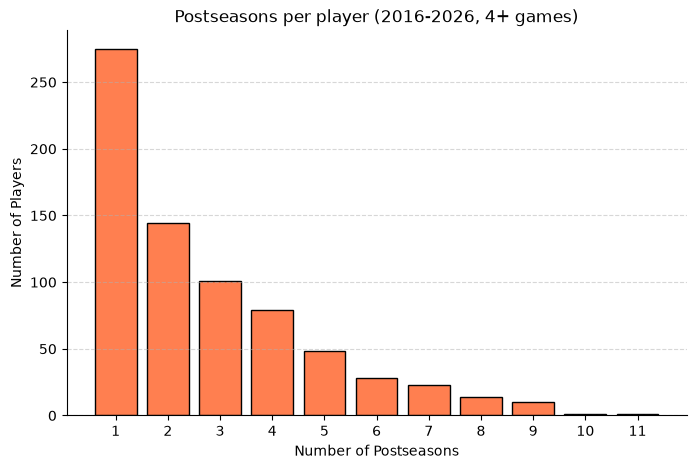

,rows,players,median_ppg,median_mpg,median_age,median_years_in_nba
appearance_group,,,,,,
1-2 postseasons,563,419,3.80,11.86,25.0,4.0
3-5 postseasons,859,228,7.71,21.85,27.0,6.0
6+ postseasons,552,77,13.36,32.77,29.0,8.0


In [9]:
po_eda_counts = po_eda.groupby('player_id').size()
print(f"Players with 4+ playoff games at least once: {len(po_eda_counts):,}")
print(f"Players with 1-2 postseasons: {(po_eda_counts <= 2).sum():,} ({(po_eda_counts <= 2).mean():.1%}); "
      f"with 6+ postseasons: {(po_eda_counts >= 6).sum():,} ({(po_eda_counts >= 6).mean():.1%})")
print(f"Most postseasons by one player: {po_eda_counts.max()}")

po_eda_rs_ids = set(df_regular_clean['player_id'])
po_eda_po_ids = set(po_eda['player_id'])
print(f"\nPlayers in the cleaned regular-season table: {len(po_eda_rs_ids):,}; "
      f"never in the cleaned playoff table: {len(po_eda_rs_ids - po_eda_po_ids):,} "
      f"({len(po_eda_rs_ids - po_eda_po_ids) / len(po_eda_rs_ids):.1%})")
print(f"Players in the cleaned playoff table but never in the cleaned regular-season table: {len(po_eda_po_ids - po_eda_rs_ids)}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(po_eda_counts, bins=range(1, po_eda_counts.max() + 2), align='left', color='coral', edgecolor='black', rwidth=0.8)
ax.set_title('Postseasons per player (2016-2026, 4+ games)')
ax.set_xlabel('Number of Postseasons')
ax.set_ylabel('Number of Players')
ax.set_xticks(range(1, po_eda_counts.max() + 1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

def po_eda_group(n):
    if n <= 2:
        return '1-2 postseasons'
    if n >= 6:
        return '6+ postseasons'
    return '3-5 postseasons'

po_eda['appearance_group'] = po_eda['player_id'].map(po_eda_counts).apply(po_eda_group)
po_eda_group_table = (po_eda.groupby('appearance_group')
                      .agg(rows=('ppg', 'size'), players=('player_id', 'nunique'),
                           median_ppg=('ppg', 'median'), median_mpg=('mpg', 'median'),
                           median_age=('age', 'median'), median_years_in_nba=('years_in_nba', 'median'))
                      .reindex(['1-2 postseasons', '3-5 postseasons', '6+ postseasons']))
display(po_eda_group_table.round(2))

### What we found

* **Most playoff players appear only once or twice:** 724 players played 4+ games in at least one postseason. 419 of them (57.9%) did it in only 1-2 postseasons, and 77 (10.6%) in 6 or more. The most by one player is 11, every postseason in the data.
* **Many players never get there:** of the 1,315 players in the regular-season view (10+ games), 597 (45.4%) never appear in the playoff view (4+ games). 6 players appear in the playoff view but not the regular-season one: every regular-season row they have has fewer than 10 games, or they have no regular-season row at all.
* **Playoff regulars have much bigger roles:** players with 6+ postseasons have a median of 13.36 `ppg` and 32.77 `mpg`, compared with 3.80 `ppg` and 11.86 `mpg` for players with 1-2. The 6+ group is also older (median age 29 vs 25) and more experienced (median 8 years vs 4).
* **Be careful:** this counts only postseasons from 2016 to 2026 with 4+ games. A player who debuted in 2024 or retired in 2017 can't have many, whatever his career was. Making the playoffs also depends mostly on the team, so the count reflects which teams a player was on as much as how good he is.

## 8. Summary of the playoff EDA

* **Playoff rosters are older and lean on fewer players.** The median age is 27 (vs 26) and the median years in the NBA 6 (vs 4). A third of playoff rows are 30+ minute players, compared with a fifth in the regular season.
* **Efficiency drops in the playoffs.** Average player TS% is lower than in the regular season in 10 of 11 seasons, and the spread is almost twice as wide (standard deviation 0.126 vs 0.069), partly because playoff samples are small.
* **On-court plus/minus means something different in the playoffs.** Its median is negative in every minute group and it is unrelated to scoring (correlation 0.02). **BPM keeps its link to scoring (0.49),** so it is the more useful playoff impact measure.
* **Games played reflects the team, not the player.** Its correlations with minutes and scoring drop by more than half compared with the regular season.
* **Playoff history is too sparse for a trend feature.** Only 18.5% of playoff rows have all three previous postseasons, and the change from that average is noisier than in the regular season. This supports keeping 3-year trends for the regular season only.
* **Questions for the next step:**
  1. Do regular-season stats predict how a player's scoring and efficiency change in the playoffs?
  2. Is the drop in playoff TS% larger for some kinds of players, such as high-minute scorers or older players?
  3. Does playoff BPM add information about trades beyond regular-season BPM, given how few players have it?